In [1]:
import pandas as pd

train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

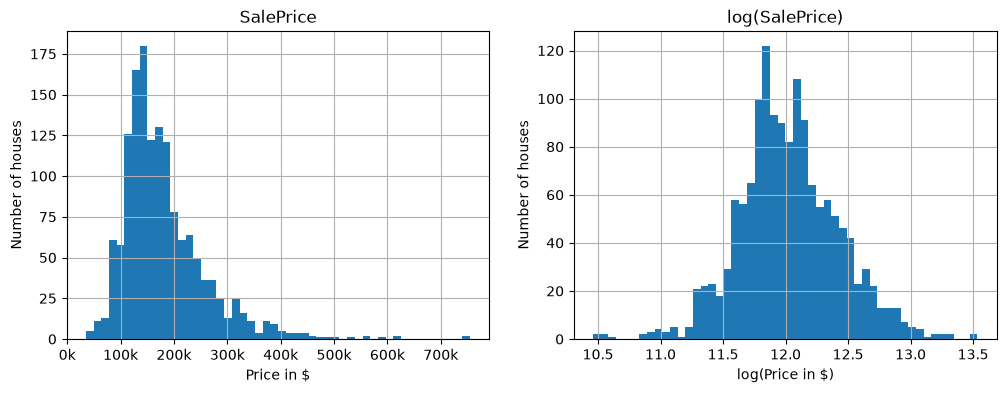

In [2]:
import matplotlib.pyplot as plt
import numpy as np

figs, axes = plt.subplots(1, 2, figsize=(12, 4))

train['SalePrice'].hist(bins=50, ax=axes[0])
axes[0].set_title('SalePrice')
axes[0].set_xlabel('Price in $')
axes[0].set_ylabel('Number of houses')

np.log(1 + train['SalePrice']).hist(bins=50, ax=axes[1])
axes[1].set_title('log(SalePrice)')
axes[1].set_xlabel('log(Price in $)')
axes[1].set_ylabel('Number of houses')

from matplotlib.ticker import FuncFormatter
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x / 1000:.0f}k'))

First observation:
* The model will working with the logarithmic value of the prices, giving a linear regression the capacity to multiply, not only add numbers
* For example, a renovated kitchen may add 10% to a house; if one house is 500k dollars, it adds 50k, and that's the number it will learn; for a 100k house, a renovated kitchen can't posibly add half of the value
* Working with log(value) turns a difference in a ratio:
	log(110.000) - log(100.000) = log(550.000) - log(500.000)
	That gives the same 0.095 weight. So multiplying by 1.10 (which we can't do in linear regression) comes down to adding 0.095 for the 10% kitchen example

Text(0, 0.5, 'Log(Price in $)')

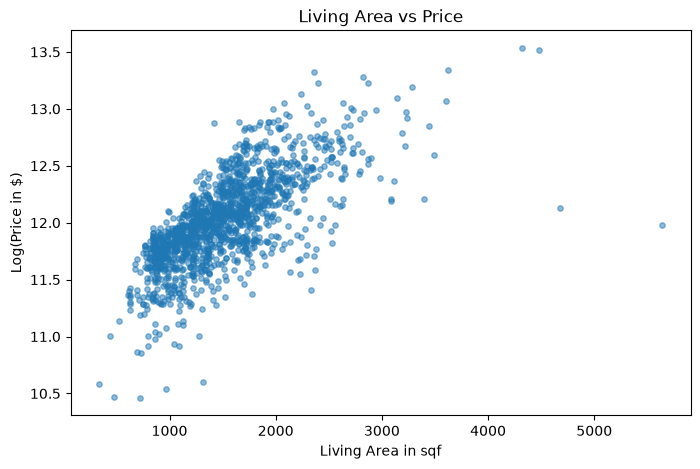

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(train['GrLivArea'], np.log(1 + train['SalePrice']), alpha=0.5, s=15)
ax.set_title('Living Area vs Price')
ax.set_xlabel('Living Area in sqf')
ax.set_ylabel('Log(Price in $)')

In [4]:
outliers = train[(train['GrLivArea'] > 4500) & (np.log(1 + train['SalePrice']) < 12.5)]
print(outliers[['SalePrice', 'GrLivArea', 'SaleCondition']])

      SalePrice  GrLivArea SaleCondition
523      184750       4676       Partial
1298     160000       5642       Partial


In [5]:
print(train.shape)
train = train.drop(outliers.index).reset_index(drop=True)
print(train.shape)

(1460, 81)
(1458, 81)


Dropped the 2 houses on the far right of the plot, which are outliers that could pull the linear regressor far right, predicting much smaller prices for each houses in the dataset.

In [6]:
missing = pd.DataFrame({
	'train': train.isnull().sum(),
	'test': test.isnull().sum(),
})

missing = missing[(missing['train'] > 0) | (missing['test'] > 0)]
missing['train%'] = (missing['train'] / len(train) * 100).round(2)

missing.sort_values('train', ascending=False)

,train,test,train%
PoolQC,1452,1456.0,99.59
MiscFeature,1404,1408.0,96.30
Alley,1367,1352.0,93.76
Fence,1177,1169.0,80.73
MasVnrType,872,894.0,59.81
FireplaceQu,690,730.0,47.33
LotFrontage,259,227.0,17.76
GarageFinish,81,78.0,5.56
GarageCond,81,78.0,5.56
GarageYrBlt,81,78.0,5.56


I viewed the columns with Null values and figured if the data is truly missing, or just 0/None, such as the case of PoolQC (only 5 houses have a pool, so the data isn't missing; there simply isn't a pool)

In [7]:
none_cols = [
	'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu',
	'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
	'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
]

zero_cols = [
	'MasVnrArea', 'GarageCars', 'GarageArea',
	'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
	'BsmtFullBath', 'BsmtHalfBath',
]

mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType']

In [8]:
def fill_missing_cols(df: pd.DataFrame) ->pd.DataFrame:
	df = df.copy()
	df[none_cols] = df[none_cols].fillna('None')
	df[zero_cols] = df[zero_cols].fillna(0)

	df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
	df['Functional'] = df['Functional'].fillna('Typ')

	df = df.drop(columns=['Utilities'])

	return df

In [9]:
def learn_values(df:pd.DataFrame) -> dict:
	return {
		'modes': df[mode_cols].mode().iloc[0],
		'lot_by_hood': df.groupby('Neighborhood')['LotFrontage'].median(),
		'lot_overall': df['LotFrontage'].median()
	}

def fill_learned(df: pd.DataFrame, values: dict) -> pd.DataFrame:
	df = df.copy()
	df[mode_cols] = df[mode_cols].fillna(values['modes'])
	df['LotFrontage'] = (
		df['LotFrontage']
		.fillna(df['Neighborhood'].map(values['lot_by_hood']))
		.fillna(values['lot_overall'])
	)
	return df

In [10]:
train = fill_missing_cols(train)
test = fill_missing_cols(test)

fill_values = learn_values(train)
train = fill_learned(train, fill_values)
test = fill_learned(test, fill_values)

Mapped the columns with missing values in 3 groups: None, 0, or truly missing
Added missing values, while learning the values only on train, not on the test data

In [11]:
ordered_encoding = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordered_cols = [
	'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu',
	'GarageQual', 'GarageCond', 'PoolQC'
]

exposure_encoding = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
garage_finish_encoding = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
finish_type_encoding = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}

ordinal_cols = ordered_cols + ['BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish']
# used later for testing

def encode_ordinal(df: pd.DataFrame) -> pd.DataFrame:
	df = df.copy()
	for col in ordered_cols:
		df[col] = df[col].map(ordered_encoding)

	df['BsmtExposure'] = df['BsmtExposure'].map(exposure_encoding)

	for col in ['BsmtFinType1', 'BsmtFinType2']:
		df[col] = df[col].map(finish_type_encoding)
	
	df['GarageFinish'] = df['GarageFinish'].map(garage_finish_encoding)

	return df

train = encode_ordinal(train)
test = encode_ordinal(test)

print(train[ordinal_cols].isnull().sum().sum(), test[ordinal_cols].isnull().sum().sum())

0 0


This was the first encoding step: the str() columns split into 2 types: ordinal ones, like Garage Condition, which can be None, Good, Average, Excelent etc, so every type was mapped with numbers, because their order matters. All the maps were taken from data_descritpion.txt

In [12]:
from sklearn.preprocessing import OneHotEncoder

train['MSSubClass'] = train['MSSubClass'].astype(str)
test['MSSubClass'] = test['MSSubClass'].astype(str)

cat_cols = [col for col in train.columns if not pd.api.types.is_numeric_dtype(train[col])]
print(len(cat_cols), cat_cols)

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).set_output(transform='pandas')
encoder.fit(train[cat_cols])

def onehot(df: pd.DataFrame) -> pd.DataFrame:
	encoded = encoder.transform(df[cat_cols])
	return pd.concat([encoded, df.drop(columns=cat_cols)], axis=1)

train = onehot(train)
test = onehot(test)

print(train.shape, test.shape)
print([col for col in train.columns if not pd.api.types.is_numeric_dtype(train[col])])

29 ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'PavedDrive', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
(1458, 256) (1459, 255)
[]


This was the second step in the encoding process, for columns whose text doesn't have an order, such as Neighborhood

In [13]:
import numpy as np
from sklearn.model_selection import KFold, cross_val_score

test_ids = test['Id']

X = train.drop(columns=['Id', 'SalePrice'])
y = np.log(1 + train['SalePrice'])
X_test = test.drop(columns=['Id'])

cv = KFold(n_splits=5, shuffle=True, random_state=67)

print(X.shape, y.shape, X_test.shape)

(1458, 254) (1458,) (1459, 254)


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), Ridge(alpha=10))
scores = cross_val_score(model, X, y, cv=cv, scoring='neg_root_mean_squared_error')

print(-scores.mean())

0.11807927672405363


In [15]:
from sklearn.dummy import DummyRegressor

baseline = cross_val_score(DummyRegressor(), X, y, cv=cv, scoring='neg_root_mean_squared_error')
print(-baseline.mean())

0.3990244313409649


Used a dummy model, which is deliberately bad (0.39 loss)
After my feature engineering, i reduced the loss to 0.12

In [20]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
	n_estimators=2000,
	learning_rate=0.05,
	max_depth=3,
	subsample=0.8,
	colsample_bytree=0.5,
	random_state=67
)

scores = cross_val_score(xgb, X, y, cv=cv, scoring='neg_root_mean_squared_error')

model = make_pipeline(StandardScaler(), xgb)
print(-scores.mean())

0.11350697017027564


In [21]:
model.fit(X, y)

log_prediction = model.predict(X_test)
prediction = np.expm1(log_prediction)

submission = pd.DataFrame({
	'Id': test_ids,
	'SalePrice': prediction,
})

submission.to_csv('data/submission.csv', index=False)